In [5]:
import yfinance
import pandas
import numpy
import sympy
import requests
import statsmodels.api as sm

# ano, mês, dia
ativo = 'PETR4.SA'
inicio = pandas.to_datetime("2021-01-01")
fim = pandas.to_datetime("2026-11-01")


def dados_ativo(ativo, inicio, fim, intervalo="1d"):
    dados = yfinance.download(
        tickers=ativo,
        start=inicio,
        end=fim,
        interval=intervalo,
        progress=False
    )
    return dados['Close'].squeeze().dropna()


def dados_dolar(inicio, fim):
    url = "https://olinda.bcb.gov.br/olinda/servico/PTAX/versao/v1/odata/CotacaoDolarPeriodo(dataInicial=@dataInicial,dataFinalCotacao=@dataFinalCotacao)"

    parametros = {
        "@dataInicial": f"'{inicio:%m-%d-%Y}'",
        "@dataFinalCotacao": f"'{fim:%m-%d-%Y}'",
        "$format": "json"
    }

    resposta = requests.get(url, params=parametros).json()
    df = pandas.DataFrame(resposta['value'])

    df['data'] = pandas.to_datetime(df['dataHoraCotacao']).dt.normalize()
    serie = df.set_index('data')['cotacaoVenda']

    return serie[~serie.index.duplicated(keep='last')]


def dados_juros(inicio, fim, codigo_serie=432):
    url = (
        f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo_serie}/dados?"
        f"formato=json&dataInicial={inicio:%d/%m/%Y}&dataFinal={fim:%d/%m/%Y}"
    )

    df = pandas.read_json(url)
    df['data'] = pandas.to_datetime(df['data'], format='%d/%m/%Y')
    serie = df.set_index('data')['valor']

    return serie[~serie.index.duplicated(keep='last')]


historico_ativo = dados_ativo(ativo, inicio, fim)
historico_dolar = dados_dolar(inicio, fim)
historico_juros = dados_juros(inicio, fim)

ativo_mensal = historico_ativo.resample('ME').last()
dolar_mensal = historico_dolar.resample('ME').last()
juros_mensal = historico_juros.resample('ME').last()

tabela_mensal = pandas.concat(
    [ativo_mensal, dolar_mensal, juros_mensal],
    axis=1
).dropna()

tabela_mensal.columns = ['PETR4', 'Dolar', 'Selic']


retornos = pandas.DataFrame()

P_t = tabela_mensal['PETR4']
P_tanterior = tabela_mensal['PETR4'].shift(1)
retornos['PETR4'] = numpy.log(P_t/P_tanterior)

D_t = tabela_mensal['Dolar']
D_tanterior = tabela_mensal['Dolar'].shift(1)
retornos['Dolar'] = numpy.log(D_t/D_tanterior)

retornos['Selic'] = tabela_mensal['Selic'].diff()/100

retornos = retornos.dropna()

#print(retornos.head())

X_matriz = numpy.column_stack([
    numpy.ones(len(retornos)),
    retornos['Dolar'],
    retornos['Selic']
])

Y = retornos['PETR4']

beta_0, beta_1, beta_2 = numpy.linalg.lstsq(X_matriz, Y, rcond=None)[0]
Y_previsto = beta_0 + beta_1 * retornos['Dolar'] + beta_2*retornos['Selic']
residuos = Y - Y_previsto

n = len(Y) # qtd de observações
k = X_matriz.shape[1] - 1 # numero de regressores excluindo o interceptto
gl_modelo = k
gl_residuos = n - k - 1
gl_total = n - 1

SQE = numpy.sum((Y - Y_previsto)**2)
SQT = numpy.sum((Y - Y.mean())**2)
r2 = 1 - (SQE/SQT)
r2_ajustado = 1 - ((1-r2) * (n - 1)/gl_residuos)

print("=== OBSERVAÇÕES, GRAUS DE LIBERDADE E R² ===")
print(f"Quantidade de observações (n): {n}")
print(f"Graus de liberdade do modelo (k): {gl_modelo}")
print(f"Graus de liberdade dos resíduos (n - k - 1): {gl_residuos}")
print(f"Graus de liberdade totais (n - 1): {gl_total}")
print(f"SQE (Soma dos Quadrados dos Erros): {SQE:.6f}")
print(f"SQT (Soma dos Quadrados Totais): {SQT:.6f}")
print(f"R² calculado manualmente: {r2:.6f}")
print(f"R² ajustado calculado manualmente: {r2_ajustado:.6f}")



x, y = sympy.symbols('x y')

f = (
    sympy.Float(beta_0) +
    sympy.Float(beta_1) * x +
    sympy.Float(beta_2) * y
)

derivada_dolar = sympy.diff(f, x)
derivada_selic = sympy.diff(f, y)

print("\n--- FUNÇÃO ECONOMÉTRICA ---")
print(f"Função ajustada: {f}")

print("\n--- DERIVADAS PARCIAIS ---")
print(f"Dólar: {derivada_dolar}")
print(f"Selic: {derivada_selic}")

X_estatistico = sm.add_constant(retornos[['Dolar', 'Selic']])
modelo = sm.OLS(Y, X_estatistico).fit(
    cov_type='HAC',
    cov_kwds={'maxlags': 3}
)

print("\n--- RESULTADOS ECONOMÉTRICOS ---")
print(modelo.summary())

print("\n--- P-VALORES ---")

for variavel, pvalor in modelo.pvalues.items():

    print(f"{variavel}: {pvalor:.6f}")

    if pvalor < 0.01:
        print("Significativo a 1%")

    elif pvalor < 0.05:
        print("Significativo a 5%")

    elif pvalor < 0.10:
        print("Significativo a 10%")

    else:
        print("Não significativo a 10%")


print("\n--- ANÁLISE DOS COEFICIENTES ---")

for variavel, coeficiente in modelo.params.items():

    if variavel == 'const':
        continue

    sinal = "Positivo" if coeficiente > 0 else "Negativo"

    print(f"\nVariável: {variavel}")
    print(f"Coeficiente: {coeficiente:.6f}")
    print(f"Sinal: {sinal}")
    print(f"Magnitude absoluta: {abs(coeficiente):.6f}")

desvio_petR4 = Y.std()

beta_dolar = (
    modelo.params['Dolar'] *
    retornos['Dolar'].std() /
    desvio_petR4
)

beta_selic = (
    modelo.params['Selic'] *
    retornos['Selic'].std() /
    desvio_petR4
)

print("\n--- SENSIBILIDADE PADRONIZADA ---")

print(f"Beta Dólar: {beta_dolar:.6f}")
print(f"Beta Selic: {beta_selic:.6f}")

if abs(beta_dolar) > abs(beta_selic):
    print("\nA PETR4 apresenta maior sensibilidade padronizada ao Dólar.")

else:
    print("\nA PETR4 apresenta maior sensibilidade padronizada à Selic.")





/tmp/ipykernel_1742/3862124791.py:15: FutureWarning: YF.download() has changed argument auto_adjust default to True
  dados = yfinance.download(


=== OBSERVAÇÕES, GRAUS DE LIBERDADE E R² ===
Quantidade de observações (n): 69
Graus de liberdade do modelo (k): 2
Graus de liberdade dos resíduos (n - k - 1): 66
Graus de liberdade totais (n - 1): 68
SQE (Soma dos Quadrados dos Erros): 0.492619
SQT (Soma dos Quadrados Totais): 0.520658
R² calculado manualmente: 0.053852
R² ajustado calculado manualmente: 0.025181

--- FUNÇÃO ECONOMÉTRICA ---
Função ajustada: -0.556391586881512*x + 1.15439201759579*y + 0.0267905966786064

--- DERIVADAS PARCIAIS ---
Dólar: -0.556391586881512
Selic: 1.15439201759579

--- RESULTADOS ECONOMÉTRICOS ---
                            OLS Regression Results                            
Dep. Variable:                  PETR4   R-squared:                       0.054
Model:                            OLS   Adj. R-squared:                  0.025
Method:                 Least Squares   F-statistic:                     3.189
Date:                Sun, 15 Nov 2026   Prob (F-statistic):             0.0476
Time:            

=== COMPARAÇÃO ENTRE ESPECIFICAÇÕES ===
             Principal (Log-Retorno)  Alt. (Retorno Simples)  \
Coef. Dólar                  -0.5564                 -0.5859   
Coef. Selic                   1.1544                  1.0151   
R²                            0.0539                  0.0550   
R² Ajustado                   0.0252                  0.0263   
AIC                        -139.1931               -135.6544   

             Alt. (Nível-Nível)  Log-Nível  Log-Log  
Coef. Dólar              7.0028     0.3420   1.8383  
Coef. Selic              2.0561     0.1227   0.8839  
R²                       0.3886     0.5528   0.5278  
R² Ajustado              0.3704     0.5394   0.5137  
AIC                    515.6969    73.4585  77.2640  

=== TESTE DE ESTACIONARIEDADE (ADF) ===

[Séries em Nível]
  PETR4  | Estatística ADF:  0.6938 | p-valor: 0.9897 | Não estacionária / Raiz unitária (p >= 0.05)
  Dolar  | Estatística ADF: -2.4379 | p-valor: 0.1313 | Não estacionária / Raiz unitária (

/tmp/ipykernel_1742/3465182131.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pval, _, _, _, _ = adfuller(df[col].dropna(), autolag='AIC')
/tmp/ipykernel_1742/3465182131.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pval, _, _, _, _ = adfuller(df[col].dropna(), autolag='AIC')
/tmp/ipykernel_1742/3465182131.py:48: FutureWarning: adfuller currently 

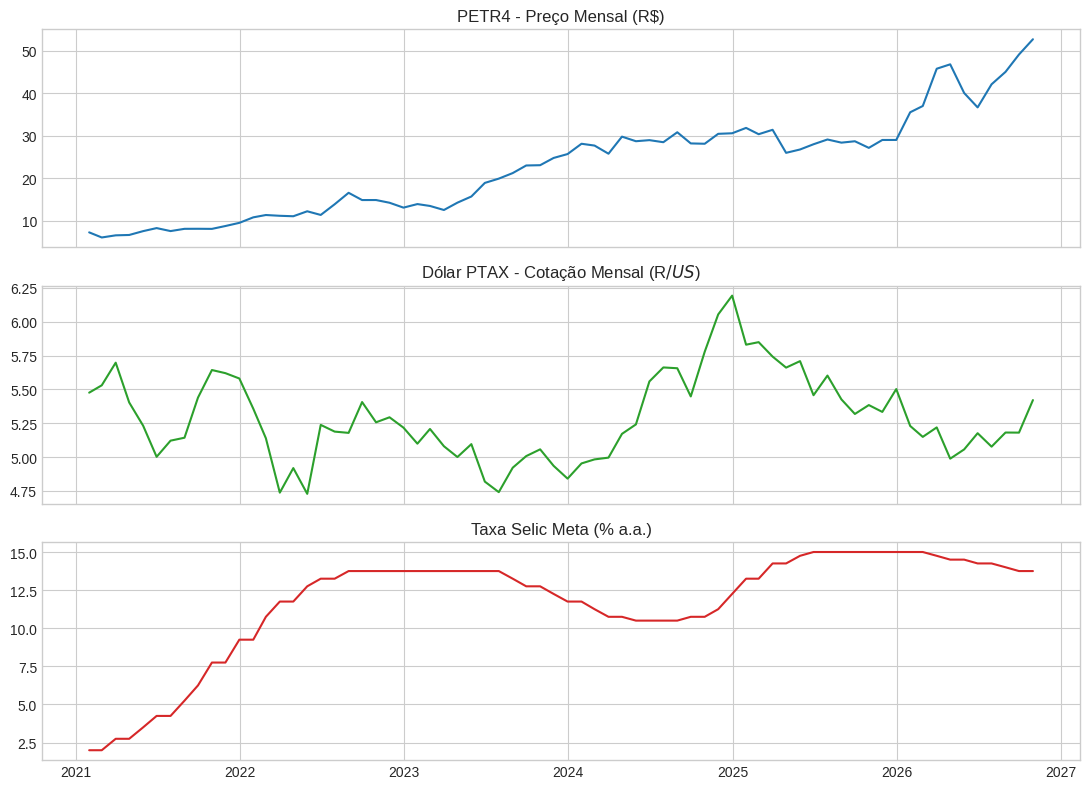

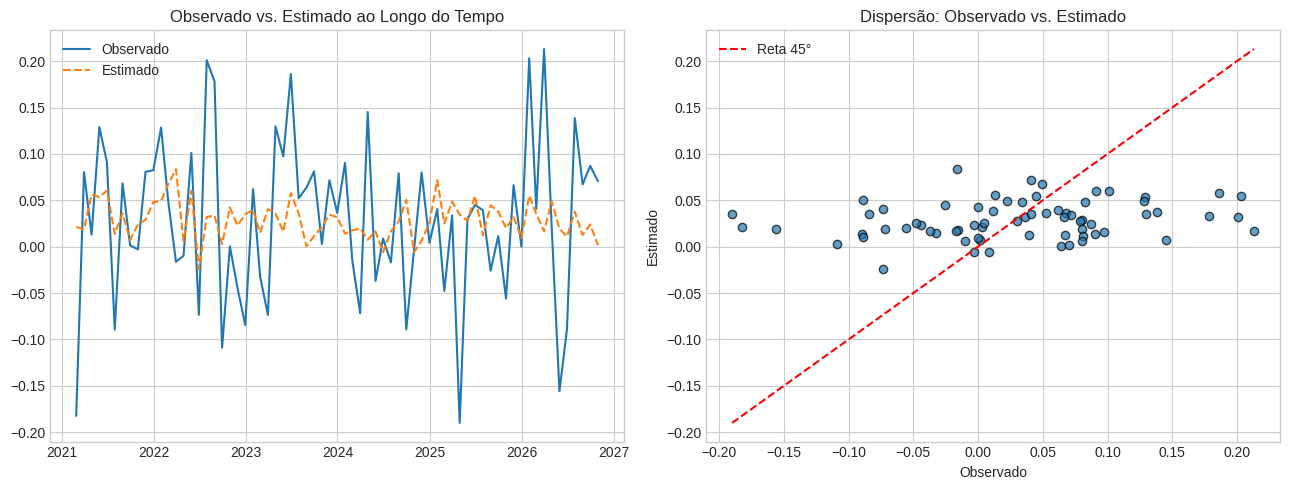

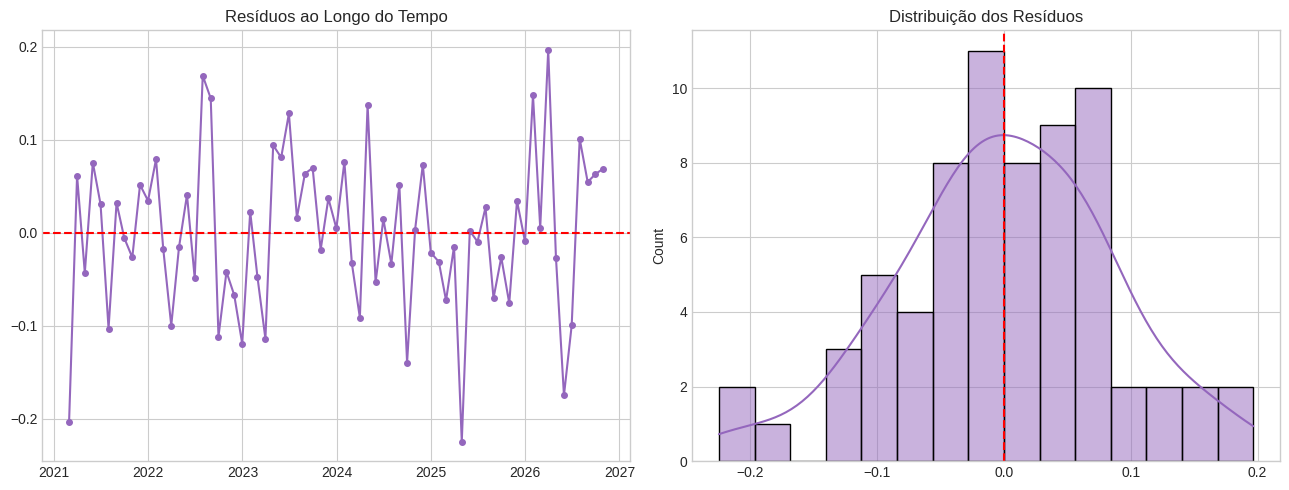

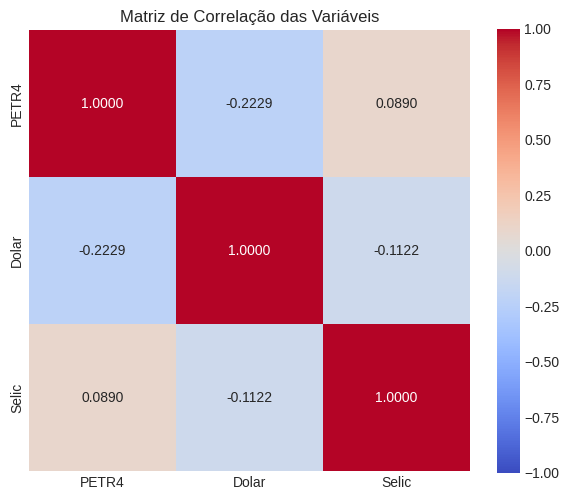

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_breusch_godfrey
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Especificações alternativas (nível-nível, retorno simples, log-nível, log-log)
X_nivel = sm.add_constant(tabela_mensal[['Dolar', 'Selic']])
modelo_nivel = sm.OLS(tabela_mensal['PETR4'], X_nivel).fit(cov_type='HAC', cov_kwds={'maxlags': 3})

# Especificação Alternativa: Retorno Percentual Simples
ret_simples = pandas.DataFrame({
    'PETR4': tabela_mensal['PETR4'].pct_change(),
    'Dolar': tabela_mensal['Dolar'].pct_change(),
    'Selic': tabela_mensal['Selic'].diff() / 100
}).dropna()
modelo_ret_simples = sm.OLS(
    ret_simples['PETR4'],
    sm.add_constant(ret_simples[['Dolar', 'Selic']])
).fit(cov_type='HAC', cov_kwds={'maxlags': 3})

# Modelo Log-Nível: ln(PETR4) = b0 + b1*Dolar + b2*Selic
y_log = numpy.log(tabela_mensal['PETR4'])
modelo_log_nivel = sm.OLS(y_log, X_nivel).fit(cov_type='HAC', cov_kwds={'maxlags': 3})

# Modelo Log-Log: ln(PETR4) = b0 + b1*ln(Dolar) + b2*ln(Selic)
X_log = sm.add_constant(numpy.log(tabela_mensal[['Dolar', 'Selic']]))
modelo_log_log = sm.OLS(y_log, X_log).fit(cov_type='HAC', cov_kwds={'maxlags': 3})

print("=== COMPARAÇÃO ENTRE ESPECIFICAÇÕES ===")
comparacao = pandas.DataFrame({
    'Principal (Log-Retorno)': [modelo.params['Dolar'], modelo.params['Selic'], modelo.rsquared, modelo.rsquared_adj, modelo.aic],
    'Alt. (Retorno Simples)': [modelo_ret_simples.params['Dolar'], modelo_ret_simples.params['Selic'], modelo_ret_simples.rsquared, modelo_ret_simples.rsquared_adj, modelo_ret_simples.aic],
    'Alt. (Nível-Nível)': [modelo_nivel.params['Dolar'], modelo_nivel.params['Selic'], modelo_nivel.rsquared, modelo_nivel.rsquared_adj, modelo_nivel.aic],
    'Log-Nível': [modelo_log_nivel.params['Dolar'], modelo_log_nivel.params['Selic'], modelo_log_nivel.rsquared, modelo_log_nivel.rsquared_adj, modelo_log_nivel.aic],
    'Log-Log': [modelo_log_log.params['Dolar'], modelo_log_log.params['Selic'], modelo_log_log.rsquared, modelo_log_log.rsquared_adj, modelo_log_log.aic],
}, index=['Coef. Dólar', 'Coef. Selic', 'R²', 'R² Ajustado', 'AIC'])
print(comparacao.round(4))


# 2. TESTE DE ESTACIONARIEDADE (ADF)

print("\n=== TESTE DE ESTACIONARIEDADE (ADF) ===")
def testar_adf(df, nome):
    print(f"\n[{nome}]")
    for col in df.columns:
        stat, pval, _, _, _, _ = adfuller(df[col].dropna(), autolag='AIC')
        status = "Estacionária (p < 0.05)" if pval < 0.05 else "Não estacionária / Raiz unitária (p >= 0.05)"
        print(f"  {col:6s} | Estatística ADF: {stat:7.4f} | p-valor: {pval:.4f} | {status}")

testar_adf(tabela_mensal, "Séries em Nível")
testar_adf(retornos, "Séries Transformadas (Retornos / Diferença)")


# 3. AUTOCORRELAÇÃO, HETEROCEDASTICIDADE (BREUSCH-PAGAN) E VIF
print("\n=== TESTE DE AUTOCORRELAÇÃO DOS RESÍDUOS ===")
dw_stat = durbin_watson(modelo.resid)
bg_lm, bg_lmpval, _, _ = acorr_breusch_godfrey(modelo, nlags=3)
print(f"Durbin-Watson: {dw_stat:.4f}")
print(f"Breusch-Godfrey (3 lags) -> LM: {bg_lm:.4f} | p-valor: {bg_lmpval:.4f}")

print("\n=== TESTE DE HETEROCEDASTICIDADE (BREUSCH-PAGAN) ===")
bp_lm, bp_lmpval, _, _ = het_breuschpagan(modelo.resid, modelo.model.exog)
print(f"Breusch-Pagan -> LM: {bp_lm:.4f} | p-valor: {bp_lmpval:.4f}")

print("\n=== CÁLCULO DO VIF (MULTICOLINEARIDADE) ===")
vif_df = pandas.DataFrame({
    "Variável": X_estatistico.columns,
    "VIF": [variance_inflation_factor(X_estatistico.values, i) for i in range(X_estatistico.shape[1])]
})
print(vif_df[vif_df['Variável'] != 'const'].to_string(index=False))

print("\n=== MATRIZ DE CORRELAÇÃO DAS VARIÁVEIS ===")
corr_matrix = retornos.corr()
print(corr_matrix.round(4))



# 4. GRÁFICOS
plt.style.use('seaborn-v0_8-whitegrid')


# Gráfico 1: Séries Temporais em Nível
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(tabela_mensal.index, tabela_mensal['PETR4'], color='#1f77b4')
axes[0].set_title('PETR4 - Preço Mensal (R$)')
axes[1].plot(tabela_mensal.index, tabela_mensal['Dolar'], color='#2ca02c')
axes[1].set_title('Dólar PTAX - Cotação Mensal (R$/US$)')
axes[2].plot(tabela_mensal.index, tabela_mensal['Selic'], color='#d62728')
axes[2].set_title('Taxa Selic Meta (% a.a.)')
plt.tight_layout()
plt.show()

# Gráfico 2: Valores Observados vs. Estimados
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(Y.index, Y, label='Observado', color='#1f77b4')
axes[0].plot(Y.index, Y_previsto, label='Estimado', color='#ff7f0e', linestyle='--')
axes[0].set_title('Observado vs. Estimado ao Longo do Tempo')
axes[0].legend()

axes[1].scatter(Y, Y_previsto, alpha=0.7, edgecolors='k')
lims = [min(Y.min(), Y_previsto.min()), max(Y.max(), Y_previsto.max())]
axes[1].plot(lims, lims, 'r--', label='Reta 45°')
axes[1].set_title('Dispersão: Observado vs. Estimado')
axes[1].set_xlabel('Observado')
axes[1].set_ylabel('Estimado')
axes[1].legend()
plt.tight_layout()
plt.show()

# Gráfico 3: Resíduos
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(residuos.index, residuos, marker='o', markersize=4, color='#9467bd')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Resíduos ao Longo do Tempo')

sns.histplot(residuos, kde=True, ax=axes[1], color='#9467bd', bins=15)
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('Distribuição dos Resíduos')
plt.tight_layout()
plt.show()

# Gráfico 4: Heatmap da Matriz de Correlação
plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".4f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title('Matriz de Correlação das Variáveis')
plt.tight_layout()
plt.show()